In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

DRIVE_DIR = "/content/drive/MyDrive/smart_agri"
print("Contents of /content/drive/MyDrive/smart_agri:")
for item in sorted(os.listdir(DRIVE_DIR)):
    full = os.path.join(DRIVE_DIR, item)
    if os.path.isfile(full):
        size_mb = os.path.getsize(full) / 1e6
        print(f"  FILE  {item}  ({size_mb:.1f} MB)")
    else:
        print(f"  DIR   {item}")

Contents of /content/drive/MyDrive/smart_agri:
  FILE  classes.txt  (0.0 MB)
  FILE  dataset_v2.zip  (1207.4 MB)


In [ ]:
import shutil, os, time

DRIVE_ZIP = "/content/drive/MyDrive/smart_agri/dataset_v2.zip"
LOCAL_ZIP = "/content/dataset_v2.zip"

# Clean up any previous runs
if os.path.exists(LOCAL_ZIP):
    os.remove(LOCAL_ZIP)
if os.path.exists("/content/dataset"):
    shutil.rmtree("/content/dataset")

t0 = time.time()
shutil.copy(DRIVE_ZIP, LOCAL_ZIP)
print(f"Copied in {time.time()-t0:.1f}s")
print(f"Local ZIP size: {os.path.getsize(LOCAL_ZIP)/1e6:.1f} MB")

Copied in 43.8s
Local ZIP size: 1207.4 MB


In [ ]:
import zipfile, time

LOCAL_DIR = "/content/dataset"
t0 = time.time()
with zipfile.ZipFile(LOCAL_ZIP, "r") as z:
    z.extractall(LOCAL_DIR)
print(f"Extracted in {time.time()-t0:.1f}s")

Extracted in 13.2s


In [ ]:
import os

print("Top of /content/dataset:")
print(os.listdir("/content/dataset"))

Top of /content/dataset:
['val', 'test', 'train']


In [ ]:
import os

DATA_ROOT = "/content/dataset"

def count_classes_and_files(split):
    folder = os.path.join(DATA_ROOT, split)
    classes = [d for d in os.listdir(folder) if os.path.isdir(os.path.join(folder, d))]
    total = 0
    for cls in classes:
        cls_dir = os.path.join(folder, cls)
        total += len([f for f in os.listdir(cls_dir)
                      if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
    return len(classes), total

for split in ("train", "val", "test"):
    n_cls, n_files = count_classes_and_files(split)
    print(f"{split:6s}: {n_cls:3d} classes, {n_files:6d} images")

train :  27 classes,  15597 images
val   :  27 classes,    372 images
test  :  27 classes,    372 images


In [ ]:
import os

def check_pure_plantdoc(split):
    folder = os.path.join(DATA_ROOT, split)
    non_pd = 0
    total = 0
    for cls in os.listdir(folder):
        cls_dir = os.path.join(folder, cls)
        if not os.path.isdir(cls_dir):
            continue
        for f in os.listdir(cls_dir):
            if not f.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            total += 1
            if not f.startswith("pd_"):
                non_pd += 1
    return total, non_pd

for split in ("val", "test"):
    total, non_pd = check_pure_plantdoc(split)
    status = "OK" if non_pd == 0 else "CONTAMINATED"
    print(f"{split}: {total} images, {non_pd} non-PlantDoc files  [{status}]")

val: 372 images, 0 non-PlantDoc files  [OK]
test: 372 images, 0 non-PlantDoc files  [OK]


In [ ]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import os
import numpy as np
import tensorflow as tf
from pathlib import Path
from collections import Counter
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_ROOT = Path("/content/dataset")
TRAIN_DIR = DATA_ROOT / "train"
VAL_DIR   = DATA_ROOT / "val"
TEST_DIR  = DATA_ROOT / "test"

# All 27 canonical classes, sorted alphabetically.
# This order defines the class index — the model's prediction i corresponds to CLASSES[i].
CLASSES = sorted([d for d in os.listdir(TRAIN_DIR) if (TRAIN_DIR / d).is_dir()])
NUM_CLASSES = len(CLASSES)

print(f"NUM_CLASSES = {NUM_CLASSES}")
for i, c in enumerate(CLASSES):
    print(f"  {i:2d}: {c}")

NUM_CLASSES = 27
   0: Apple___Apple_scab
   1: Apple___Cedar_apple_rust
   2: Apple___healthy
   3: Blueberry___healthy
   4: Cherry___healthy
   5: Corn___Cercospora_leaf_spot
   6: Corn___Common_rust
   7: Corn___Northern_Leaf_Blight
   8: Grape___Black_rot
   9: Grape___healthy
  10: Peach___healthy
  11: Pepper__bell___Bacterial_spot
  12: Pepper__bell___healthy
  13: Potato___Early_blight
  14: Potato___Late_blight
  15: Raspberry___healthy
  16: Soybean___healthy
  17: Squash___Powdery_mildew
  18: Strawberry___healthy
  19: Tomato___Bacterial_spot
  20: Tomato___Early_blight
  21: Tomato___Late_blight
  22: Tomato___Leaf_Mold
  23: Tomato___Septoria_leaf_spot
  24: Tomato___Tomato_mosaic_virus
  25: Tomato___Yellow_Leaf_Curl_Virus
  26: Tomato___healthy


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def list_files_with_labels(split_dir, class_list):
    paths, labels = [], []
    for idx, cls in enumerate(class_list):
        folder = split_dir / cls
        if not folder.is_dir():
            continue
        for f in sorted(folder.iterdir()):
            if f.suffix.lower() in (".jpg", ".jpeg", ".png"):
                paths.append(str(f))
                labels.append(idx)
    return paths, labels

train_paths, train_labels = list_files_with_labels(TRAIN_DIR, CLASSES)
val_paths,   val_labels   = list_files_with_labels(VAL_DIR,   CLASSES)
test_paths,  test_labels  = list_files_with_labels(TEST_DIR,  CLASSES)

print(f"Train: {len(train_paths)}")
print(f"Val:   {len(val_paths)}")
print(f"Test:  {len(test_paths)}")

# Sanity check: how many train images per class?
train_counts = Counter(train_labels)
print("\nTrain per class:")
for i, cls in enumerate(CLASSES):
    print(f"  {train_counts.get(i, 0):5d}  {cls}")

Train: 15597
Val:   372
Test:  372

Train per class:
    617  Apple___Apple_scab
    337  Apple___Cedar_apple_rust
    615  Apple___healthy
    631  Blueberry___healthy
    591  Cherry___healthy
    561  Corn___Cercospora_leaf_spot
    632  Corn___Common_rust
    685  Corn___Northern_Leaf_Blight
    596  Grape___Black_rot
    472  Grape___healthy
    439  Peach___healthy
    601  Pepper__bell___Bacterial_spot
    593  Pepper__bell___healthy
    632  Potato___Early_blight
    625  Potato___Late_blight
    456  Raspberry___healthy
    597  Soybean___healthy
    642  Squash___Powdery_mildew
    524  Strawberry___healthy
    628  Tomato___Bacterial_spot
    612  Tomato___Early_blight
    629  Tomato___Late_blight
    615  Tomato___Leaf_Mold
    657  Tomato___Septoria_leaf_spot
    411  Tomato___Tomato_mosaic_virus
    604  Tomato___Yellow_Leaf_Curl_Virus
    595  Tomato___healthy


In [ ]:
# Field-style augmentation
train_aug = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomBrightness(0.2),
    tf.keras.layers.RandomContrast(0.2),
], name="train_aug")

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def augment(img, label):
    img = train_aug(img, training=True)
    return img, label

def make_ds(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_ds(train_paths, train_labels, training=True)
val_ds   = make_ds(val_paths,   val_labels,   training=False)
test_ds  = make_ds(test_paths,  test_labels,  training=False)

print(f"Batches — train: {len(train_ds)}, val: {len(val_ds)}, test: {len(test_ds)}")

Batches — train: 488, val: 12, test: 12


In [ ]:
base = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
)
base.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 27)             │        34,587 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,292,571 (8.75 MB)

 Trainable params: 34,587 (135.11 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
CKPT_DIR = "/content/drive/MyDrive/smart_agri/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

EPOCHS_STAGE1 = 8

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

ckpt1 = tf.keras.callbacks.ModelCheckpoint(
    f"{CKPT_DIR}/stage1_best.keras",
    monitor="val_accuracy", mode="max", save_best_only=True, verbose=1,
)

history1 = model.fit(
    train_ds, validation_data=val_ds,
    epochs=EPOCHS_STAGE1,
    callbacks=[ckpt1],
)

Epoch 1/8
488/488 ━━━━━━━━━━━━━━━━━━━━ 0s 430ms/step - accuracy: 0.0471 - loss: 3.4907
Epoch 1: val_accuracy improved from None to 0.10484, saving model to /content/drive/MyDrive/smart_agri/checkpoints/stage1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/smart_agri/checkpoints/stage1_best.keras
488/488 ━━━━━━━━━━━━━━━━━━━━ 238s 456ms/step - accuracy: 0.0519 - loss: 3.4290 - val_accuracy: 0.1048 - val_loss: 3.3645
Epoch 2/8
488/488 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step - accuracy: 0.0639 - loss: 3.3370
Epoch 2: val_accuracy improved from 0.10484 to 0.15054, saving model to /content/drive/MyDrive/smart_agri/checkpoints/stage1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/smart_agri/checkpoints/stage1_best.keras
488/488 ━━━━━━━━━━━━━━━━━━━━ 242s 435ms/step - accuracy: 0.0698 - loss: 3.3169 - val_accuracy: 0.1505 - val_loss: 3.2288
Epoch 3/8
488/488 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step - accuracy: 0.0765 - loss: 3.2648
Epoch 3: val_accuracy improved

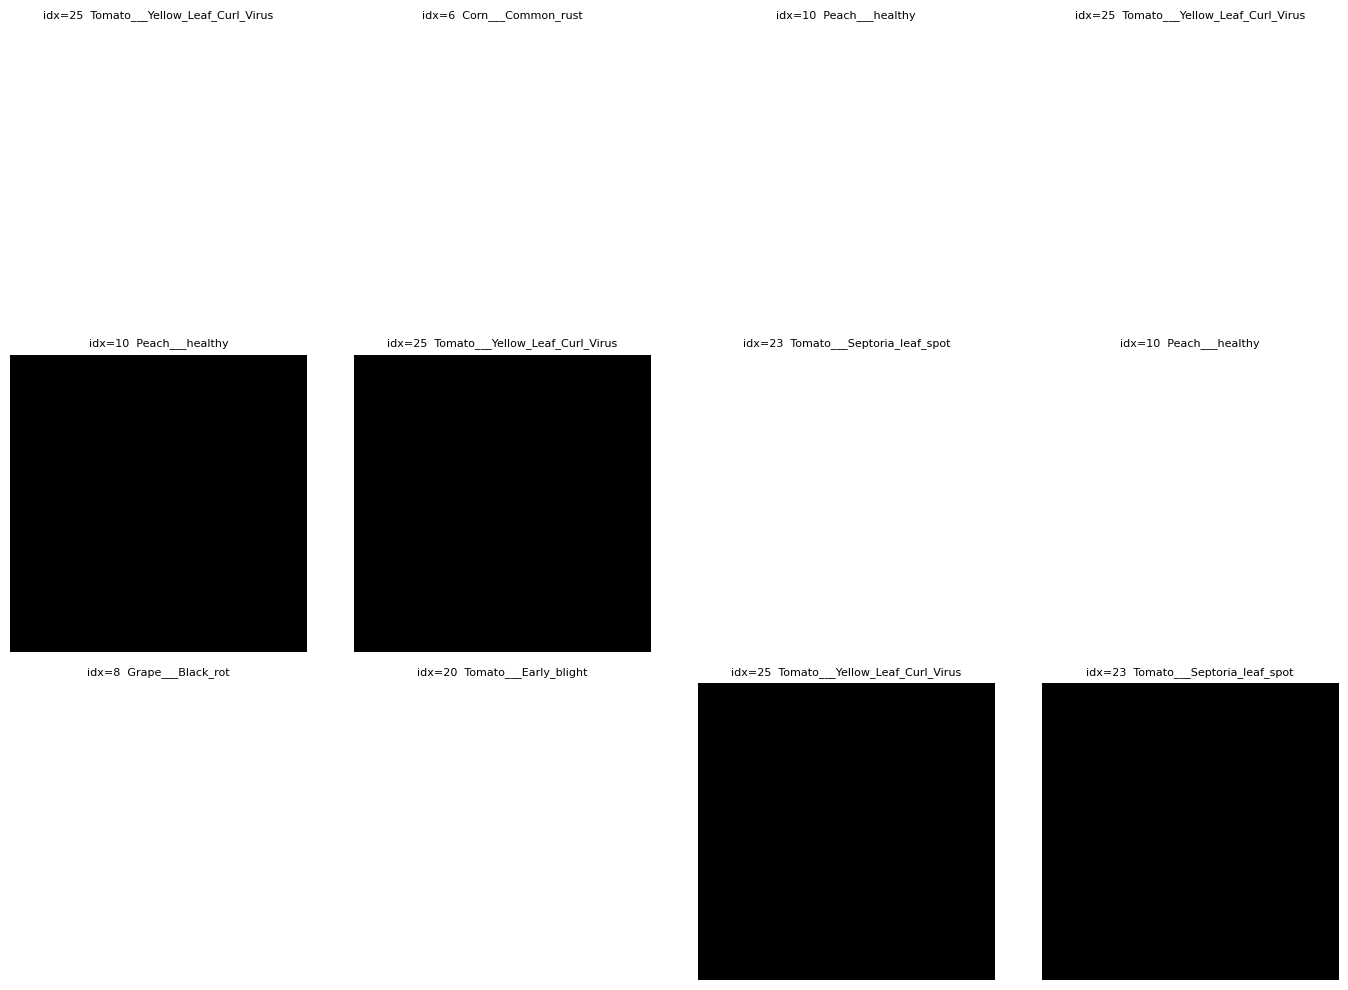

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Grab one batch from the training set
for images, labels in train_ds.take(1):
    break

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, img, lbl in zip(axes.flat, images[:12], labels[:12]):
    ax.imshow(img.numpy())
    ax.set_title(f"idx={int(lbl)}  {CLASSES[int(lbl)]}", fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/smart_agri/label_check.png", dpi=100)
plt.show()

In [ ]:
from collections import Counter
counts = Counter(train_labels)
print("Per-class train counts (sorted by count):")
for cls_idx, n in sorted(counts.items(), key=lambda x: x[1]):
    print(f"  {n:5d}  {CLASSES[cls_idx]}")

Per-class train counts (sorted by count):
    337  Apple___Cedar_apple_rust
    411  Tomato___Tomato_mosaic_virus
    439  Peach___healthy
    456  Raspberry___healthy
    472  Grape___healthy
    524  Strawberry___healthy
    561  Corn___Cercospora_leaf_spot
    591  Cherry___healthy
    593  Pepper__bell___healthy
    595  Tomato___healthy
    596  Grape___Black_rot
    597  Soybean___healthy
    601  Pepper__bell___Bacterial_spot
    604  Tomato___Yellow_Leaf_Curl_Virus
    612  Tomato___Early_blight
    615  Apple___healthy
    615  Tomato___Leaf_Mold
    617  Apple___Apple_scab
    625  Potato___Late_blight
    628  Tomato___Bacterial_spot
    629  Tomato___Late_blight
    631  Blueberry___healthy
    632  Corn___Common_rust
    632  Potato___Early_blight
    642  Squash___Powdery_mildew
    657  Tomato___Septoria_leaf_spot
    685  Corn___Northern_Leaf_Blight


Image tensor stats (no augmentation):
  min:  0.0000
  max:  1.0000
  mean: 0.4961


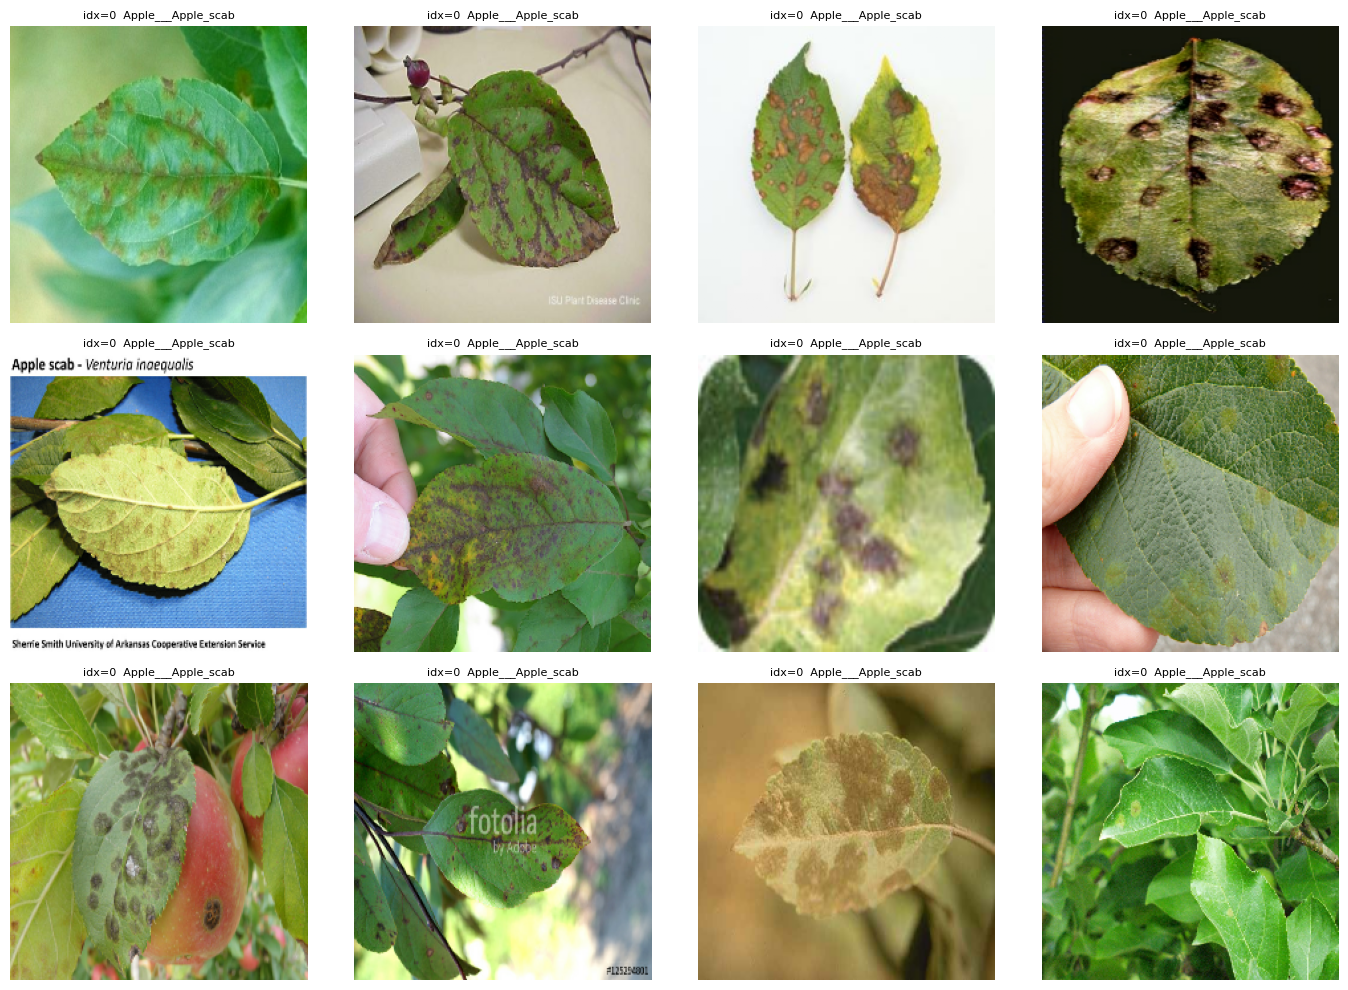

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Rebuild a dataset WITHOUT augmentation for inspection
def load_image_noaug(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (224, 224))
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

inspect_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
inspect_ds = inspect_ds.map(load_image_noaug).batch(12)

for images, labels in inspect_ds.take(1):
    break

print("Image tensor stats (no augmentation):")
print(f"  min:  {float(images.numpy().min()):.4f}")
print(f"  max:  {float(images.numpy().max()):.4f}")
print(f"  mean: {float(images.numpy().mean()):.4f}")

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, img, lbl in zip(axes.flat, images[:12], labels[:12]):
    ax.imshow(img.numpy())
    ax.set_title(f"idx={int(lbl)}  {CLASSES[int(lbl)]}", fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/smart_agri/label_check_noaug.png", dpi=100)
plt.show()

In [ ]:
# Replacement augmentation — no RandomContrast
train_aug = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.15, fill_mode="nearest"),
    tf.keras.layers.RandomZoom(0.15, fill_mode="nearest"),
    tf.keras.layers.RandomBrightness(0.15),
], name="train_aug")

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def augment(img, label):
    img = train_aug(img, training=True)
    return img, label

def make_ds(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_ds(train_paths, train_labels, training=True)
val_ds   = make_ds(val_paths,   val_labels,   training=False)
test_ds  = make_ds(test_paths,  test_labels,  training=False)

print(f"Datasets rebuilt — train: {len(train_ds)}, val: {len(val_ds)}, test: {len(test_ds)}")

Datasets rebuilt — train: 488, val: 12, test: 12


Augmented batch stats (AFTER fix):
  min:  0.0000
  max:  28.6057
  mean: 6.3756
  non-zero fraction: 0.4375


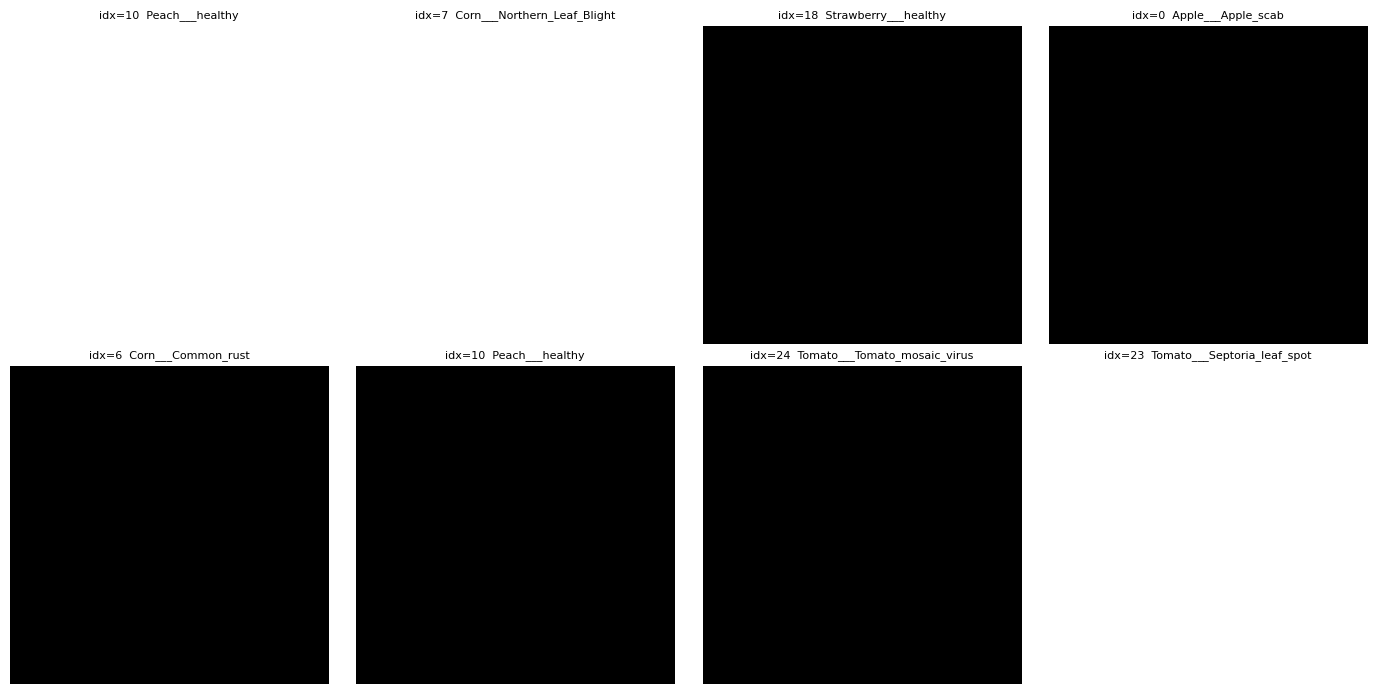

In [ ]:
for images, labels in train_ds.take(1):
    break

print("Augmented batch stats (AFTER fix):")
print(f"  min:  {float(images.numpy().min()):.4f}")
print(f"  max:  {float(images.numpy().max()):.4f}")
print(f"  mean: {float(images.numpy().mean()):.4f}")
print(f"  non-zero fraction: {(images.numpy() > 0.01).mean():.4f}")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, img, lbl in zip(axes.flat, images[:8], labels[:8]):
    ax.imshow(img.numpy())
    ax.set_title(f"idx={int(lbl)}  {CLASSES[int(lbl)]}", fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
for images, labels in train_ds.take(1):
    break

arr = images.numpy()
print(f"min:  {arr.min():.6f}")
print(f"max:  {arr.max():.6f}")
print(f"mean: {arr.mean():.6f}")
print(f"std:  {arr.std():.6f}")
print(f"non-zero fraction (pixels > 0.01): {(arr > 0.01).mean():.6f}")

min:  0.000000
max:  38.754860
mean: 8.153938
std:  10.612229
non-zero fraction (pixels > 0.01): 0.615868


In [ ]:
def augment(img, label):
    # img is float32 in [0, 1]
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    # Brightness: multiply by a factor in [0.85, 1.15] — stays in [0, 1] after clipping
    img = tf.image.random_brightness(img, max_delta=0.15)
    img = tf.image.random_contrast(img, lower=0.85, upper=1.15)
    # Rotation & zoom via Keras, but on uint8 to avoid the internal /255
    # Easiest: skip these two for now, add them back if needed
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img, label

In [ ]:
def make_ds(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_ds(train_paths, train_labels, training=True)
val_ds   = make_ds(val_paths,   val_labels,   training=False)
test_ds  = make_ds(test_paths,  test_labels,  training=False)
print(f"Rebuilt — train: {len(train_ds)}, val: {len(val_ds)}, test: {len(test_ds)}")

Rebuilt — train: 488, val: 12, test: 12


min:  0.000000
max:  1.000000
mean: 0.444918
std:  0.221501
non-zero fraction: 0.965746


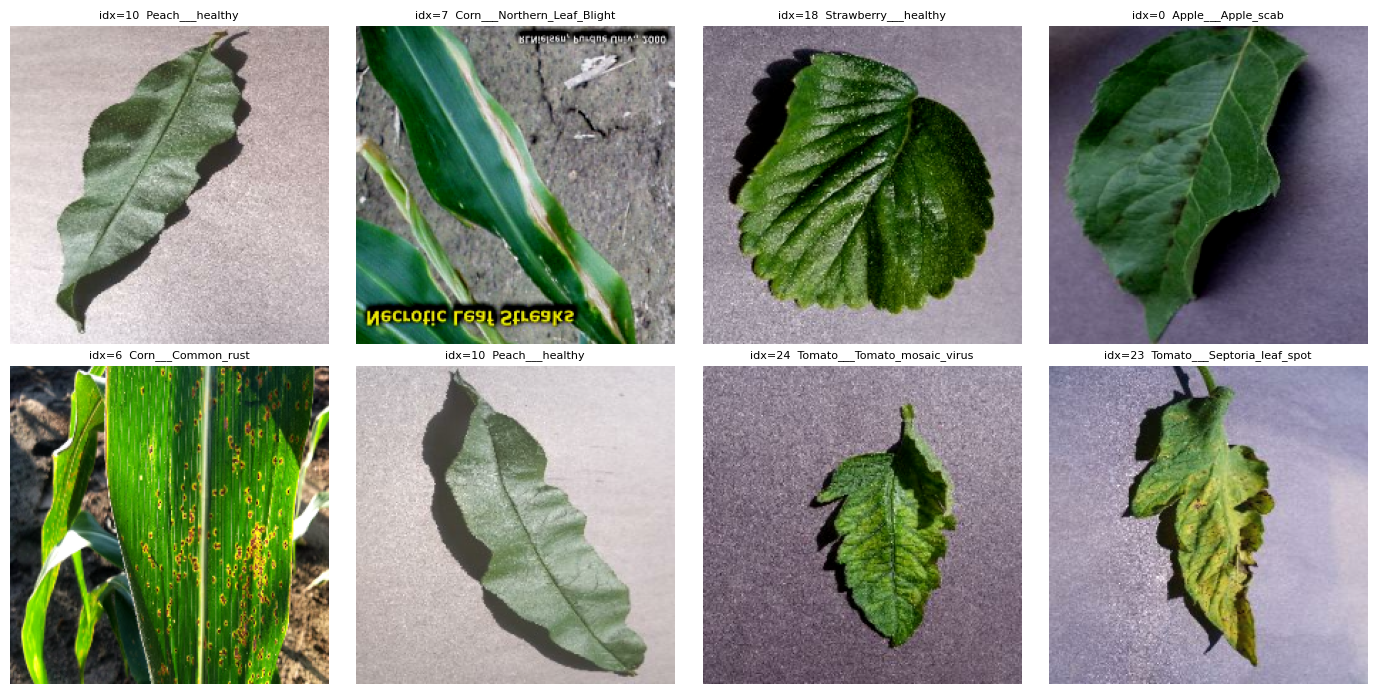

In [ ]:
for images, labels in train_ds.take(1):
    break

arr = images.numpy()
print(f"min:  {arr.min():.6f}")
print(f"max:  {arr.max():.6f}")
print(f"mean: {arr.mean():.6f}")
print(f"std:  {arr.std():.6f}")
print(f"non-zero fraction: {(arr > 0.01).mean():.6f}")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, img, lbl in zip(axes.flat, images[:8], labels[:8]):
    ax.imshow(img.numpy())
    ax.set_title(f"idx={int(lbl)}  {CLASSES[int(lbl)]}", fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
import os, shutil

CKPT_DIR = "/content/drive/MyDrive/smart_agri/checkpoints"
if os.path.exists(CKPT_DIR):
    shutil.rmtree(CKPT_DIR)
os.makedirs(CKPT_DIR, exist_ok=True)
print("Old checkpoints cleared.")

Old checkpoints cleared.


In [ ]:
base = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
)
base.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 27)             │        34,587 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,292,571 (8.75 MB)

 Trainable params: 34,587 (135.11 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
EPOCHS_STAGE1 = 8

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

ckpt1 = tf.keras.callbacks.ModelCheckpoint(
    f"{CKPT_DIR}/stage1_best.keras",
    monitor="val_accuracy", mode="max", save_best_only=True, verbose=1,
)

history1 = model.fit(
    train_ds, validation_data=val_ds,
    epochs=EPOCHS_STAGE1,
    callbacks=[ckpt1],
)

Epoch 1/8
488/488 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.5447 - loss: 1.6552
Epoch 1: val_accuracy improved from None to 0.43011, saving model to /content/drive/MyDrive/smart_agri/checkpoints/stage1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/smart_agri/checkpoints/stage1_best.keras
488/488 ━━━━━━━━━━━━━━━━━━━━ 64s 111ms/step - accuracy: 0.7047 - loss: 1.0668 - val_accuracy: 0.4301 - val_loss: 1.9317
Epoch 2/8
487/488 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.8242 - loss: 0.5949
Epoch 2: val_accuracy improved from 0.43011 to 0.47043, saving model to /content/drive/MyDrive/smart_agri/checkpoints/stage1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/smart_agri/checkpoints/stage1_best.keras
488/488 ━━━━━━━━━━━━━━━━━━━━ 47s 96ms/step - accuracy: 0.8328 - loss: 0.5701 - val_accuracy: 0.4704 - val_loss: 1.6899
Epoch 3/8
487/488 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.8549 - loss: 0.4752
Epoch 3: val_accuracy improved from 

In [ ]:
import json

# Save the trained model (Stage 1 final state)
model.save("/content/drive/MyDrive/smart_agri/stage1_final.keras")

# Save the class list — needed to decode predictions later
with open("/content/drive/MyDrive/smart_agri/classes.json", "w") as f:
    json.dump(CLASSES, f, indent=2)

print("Saved:")
print("  /content/drive/MyDrive/smart_agri/stage1_final.keras")
print("  /content/drive/MyDrive/smart_agri/classes.json")
print(f"  {len(CLASSES)} classes")

Saved:
  /content/drive/MyDrive/smart_agri/stage1_final.keras
  /content/drive/MyDrive/smart_agri/classes.json
  27 classes


In [ ]:
import os, shutil, time, json, random
from pathlib import Path
from collections import Counter
import numpy as np
import tensorflow as tf

# ---- 1. Mount Drive ----
from google.colab import drive
drive.mount('/content/drive')

# ---- 2. Extract dataset if needed ----
DRIVE_ZIP = "/content/drive/MyDrive/smart_agri/dataset_v2.zip"
LOCAL_ZIP = "/content/dataset_v2.zip"
DATA_ROOT = Path("/content/dataset")

if not (DATA_ROOT / "train").is_dir():
    print("Extracting dataset from Drive ZIP (3-5 minutes)...")
    if not os.path.exists(LOCAL_ZIP):
        t0 = time.time()
        shutil.copy(DRIVE_ZIP, LOCAL_ZIP)
        print(f"  Copied in {time.time()-t0:.1f}s")
    t0 = time.time()
    import zipfile
    with zipfile.ZipFile(LOCAL_ZIP, "r") as z:
        z.extractall(str(DATA_ROOT))
    print(f"  Extracted in {time.time()-t0:.1f}s")
else:
    print("Dataset already present.")

# ---- 3. Reproducibility ----
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- 4. Paths and classes ----
TRAIN_DIR = DATA_ROOT / "train"
VAL_DIR   = DATA_ROOT / "val"
TEST_DIR  = DATA_ROOT / "test"

with open("/content/drive/MyDrive/smart_agri/classes.json") as f:
    CLASSES = json.load(f)
NUM_CLASSES = len(CLASSES)
print(f"Loaded {NUM_CLASSES} classes")

# ---- 5. File lists ----
def list_files_with_labels(split_dir, class_list):
    paths, labels = [], []
    for idx, cls in enumerate(class_list):
        folder = split_dir / cls
        if not folder.is_dir():
            continue
        for f in sorted(folder.iterdir()):
            if f.suffix.lower() in (".jpg", ".jpeg", ".png"):
                paths.append(str(f)); labels.append(idx)
    return paths, labels

train_paths, train_labels = list_files_with_labels(TRAIN_DIR, CLASSES)
val_paths,   val_labels   = list_files_with_labels(VAL_DIR,   CLASSES)
test_paths,  test_labels  = list_files_with_labels(TEST_DIR,  CLASSES)

# ---- 6. Constants ----
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# ---- 7. FIXED augmentation (no RandomBrightness from Keras) ----
def augment(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.15)
    img = tf.image.random_contrast(img, lower=0.85, upper=1.15)
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img, label

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def make_ds(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(augment, num_autune := AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_ds(train_paths, train_labels, training=True)
val_ds   = make_ds(val_paths,   val_labels,   training=False)
test_ds  = make_ds(test_paths,  test_labels,  training=False)

print(f"Train: {len(train_paths)} | Val: {len(val_paths)} | Test: {len(test_paths)}")
print(f"GPU: {tf.config.list_physical_devices('GPU')}")

Mounted at /content/drive
Extracting dataset from Drive ZIP (3-5 minutes)...
  Copied in 20.6s
  Extracted in 7.9s
Loaded 27 classes
Train: 15597 | Val: 372 | Test: 372
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
CKPT_DIR = "/content/drive/MyDrive/smart_agri/checkpoints"
STAGE1_FINAL = "/content/drive/MyDrive/smart_agri/stage1_final.keras"
STAGE1_BEST  = f"{CKPT_DIR}/stage1_best.keras"

# Try the "final" first, fall back to the "best" checkpoint
load_path = STAGE1_FINAL if os.path.exists(STAGE1_FINAL) else STAGE1_BEST

model = tf.keras.models.load_model(load_path)
print(f"Loaded: {load_path}")
model.summary()

# Recover the MobileNetV2 base layer from the loaded model
base = None
for layer in model.layers:
    if isinstance(layer, tf.keras.Model) and "mobilenet" in layer.name.lower():
        base = layer
        break

if base is None:
    raise RuntimeError("Could not find MobileNetV2 base in loaded model. "
                       "Print model.layers and paste the list.")
print(f"\nFound base: {base.name}")
print(f"Base layers: {len(base.layers)}")

Loaded: /content/drive/MyDrive/smart_agri/stage1_final.keras


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 27)             │        34,587 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,361,747 (9.01 MB)

 Trainable params: 34,587 (135.11 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 69,176 (270.22 KB)


Found base: mobilenetv2_1.00_224
Base layers: 154


In [ ]:
loss, acc = model.evaluate(val_ds, verbose=0)
print(f"Stage 1 model — val_loss: {loss:.4f}, val_accuracy: {acc:.4f}")

Stage 1 model — val_loss: 1.6051, val_accuracy: 0.5349


In [ ]:
print(f"Base found: {base.name if 'base' in dir() and base is not None else 'NOT FOUND'}")

Base found: mobilenetv2_1.00_224


In [ ]:
EPOCHS_STAGE2 = 10

# Unfreeze top MobileNetV2 blocks
for i, layer in enumerate(base.layers):
    if i >= 14:
        layer.trainable = True

# Keep BatchNorm frozen
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

ckpt2 = tf.keras.callbacks.ModelCheckpoint(
    f"{CKPT_DIR}/stage2_best.keras",
    monitor="val_accuracy", mode="max", save_best_only=True, verbose=1,
)
lr_sched = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1,
)

history2 = model.fit(
    train_ds, validation_data=val_ds,
    epochs=EPOCHS_STAGE2,
    callbacks=[ckpt2, lr_sched],
)

Epoch 1/10
488/488 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.8979 - loss: 0.3142
Epoch 1: val_accuracy improved from None to 0.56452, saving model to /content/drive/MyDrive/smart_agri/checkpoints/stage2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/smart_agri/checkpoints/stage2_best.keras
488/488 ━━━━━━━━━━━━━━━━━━━━ 113s 166ms/step - accuracy: 0.9068 - loss: 0.2843 - val_accuracy: 0.5645 - val_loss: 1.5410 - learning_rate: 1.0000e-05
Epoch 2/10
487/488 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.9231 - loss: 0.2366
Epoch 2: val_accuracy improved from 0.56452 to 0.56720, saving model to /content/drive/MyDrive/smart_agri/checkpoints/stage2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/smart_agri/checkpoints/stage2_best.keras
488/488 ━━━━━━━━━━━━━━━━━━━━ 56s 114ms/step - accuracy: 0.9245 - loss: 0.2337 - val_accuracy: 0.5672 - val_loss: 1.4677 - learning_rate: 1.0000e-05
Epoch 3/10
487/488 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accu

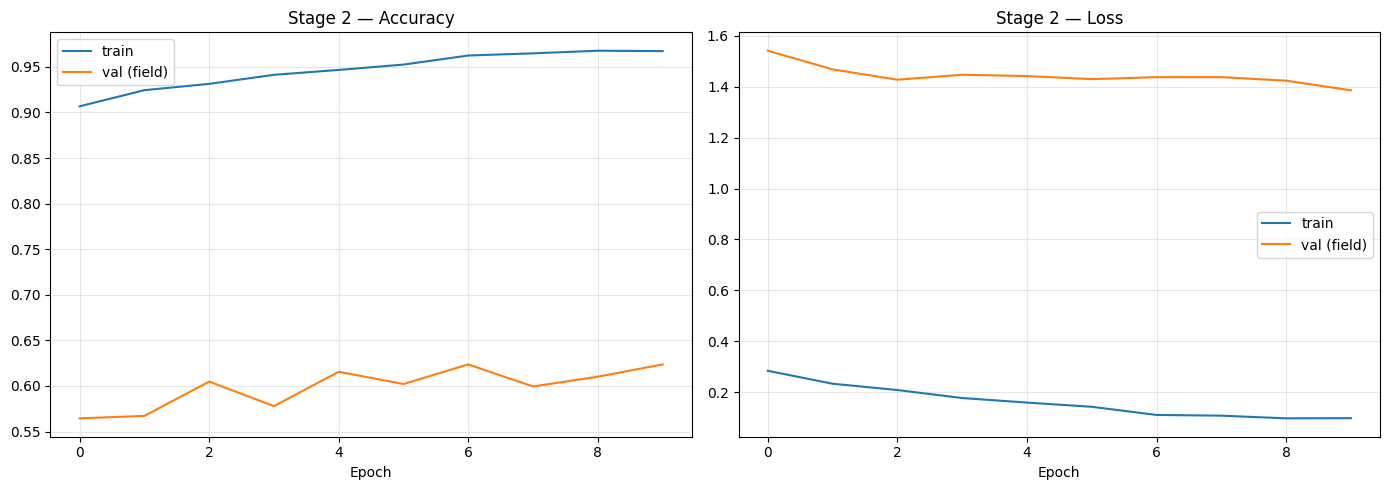

Saved:
  mobilenetv2_final.keras
  training_curves.png


In [ ]:
import shutil
import matplotlib.pyplot as plt

# Save a copy of the final model
shutil.copy(
    "/content/drive/MyDrive/smart_agri/checkpoints/stage2_best.keras",
    "/content/drive/MyDrive/smart_agri/mobilenetv2_final.keras",
)

# Plot Stage 2 only
acc = history2.history["accuracy"]
val_acc = history2.history["val_accuracy"]
loss = history2.history["loss"]
val_loss = history2.history["val_loss"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(acc, label="train"); ax1.plot(val_acc, label="val (field)")
ax1.set_title("Stage 2 — Accuracy"); ax1.set_xlabel("Epoch"); ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(loss, label="train"); ax2.plot(val_loss, label="val (field)")
ax2.set_title("Stage 2 — Loss"); ax2.set_xlabel("Epoch"); ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/smart_agri/training_curves.png", dpi=100)
plt.show()

print("Saved:")
print("  mobilenetv2_final.keras")
print("  training_curves.png")

In [ ]:
import tensorflow as tf

# Load the best Stage 2 checkpoint
best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/smart_agri/checkpoints/stage2_best.keras"
)

# Evaluate on the test set — ONE TIME ONLY, no more decisions after this
test_loss, test_acc = best_model.evaluate(test_ds, verbose=0)
print(f"TEST accuracy (field-only, 372 images): {test_acc:.4f}")
print(f"TEST loss: {test_loss:.4f}")

TEST accuracy (field-only, 372 images): 0.5403
TEST loss: 1.6130


Test accuracy (recomputed): 0.5403

Per-class accuracy:
  Apple___Apple_scab                           13 samples   acc=61.54%
  Apple___Cedar_apple_rust                     13 samples   acc=23.08%
  Apple___healthy                              13 samples   acc=61.54%
  Blueberry___healthy                          17 samples   acc=64.71%
  Cherry___healthy                              8 samples   acc=37.50%
  Corn___Cercospora_leaf_spot                  10 samples   acc=30.00%
  Corn___Common_rust                           17 samples   acc=70.59%
  Corn___Northern_Leaf_Blight                  28 samples   acc=71.43%
  Grape___Black_rot                             9 samples   acc=77.78%
  Grape___healthy                              10 samples   acc=80.00%
  Peach___healthy                              16 samples   acc=62.50%
  Pepper__bell___Bacterial_spot                10 samples   acc=50.00%
  Pepper__bell___healthy                        9 samples   acc=66.67%
  Potato___Early_blig

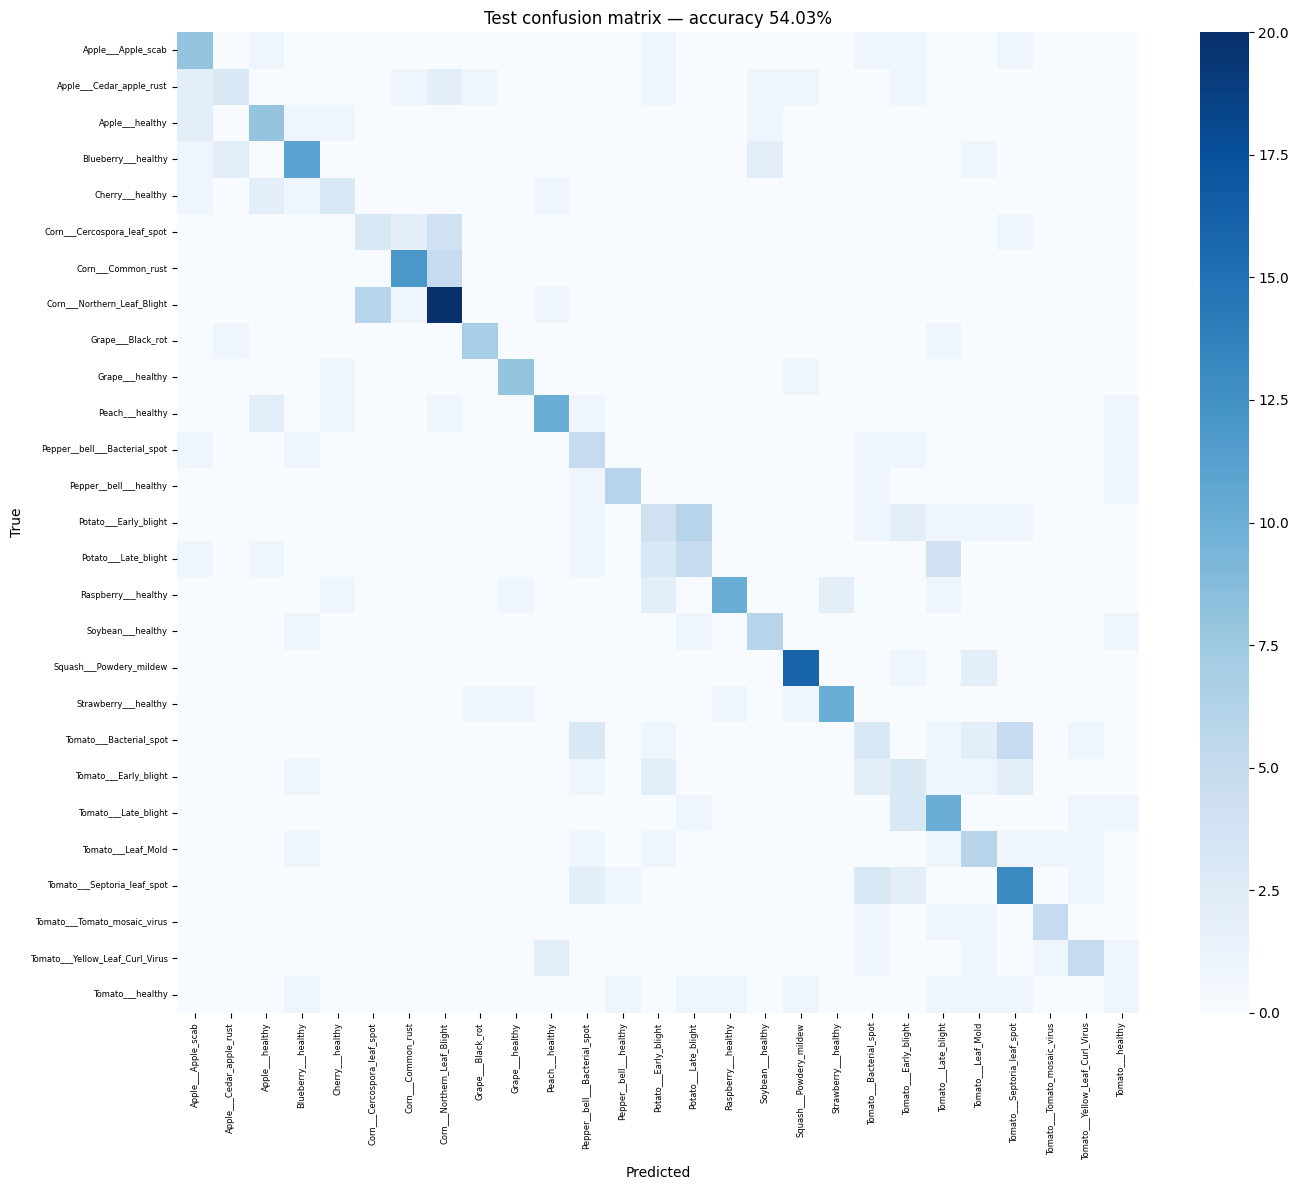

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Collect predictions
all_preds = []
all_labels = []
for images, labels in test_ds:
    preds = best_model.predict(images, verbose=0)
    all_preds.extend(np.argmax(preds, axis=1))
    all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Overall accuracy
print(f"Test accuracy (recomputed): {(all_preds == all_labels).mean():.4f}")

# Per-class
print("\nPer-class accuracy:")
for i, cls in enumerate(CLASSES):
    mask = all_labels == i
    if mask.sum() == 0:
        continue
    cls_acc = (all_preds[mask] == i).mean()
    print(f"  {cls:42s}  {mask.sum():3d} samples   acc={cls_acc:.2%}")

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds, labels=range(len(CLASSES)))
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, annot=False, cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Test confusion matrix — accuracy {(all_preds == all_labels).mean():.2%}")
plt.xticks(rotation=90, fontsize=6); plt.yticks(fontsize=6)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/smart_agri/test_confusion_matrix.png", dpi=120)
plt.show()

In [ ]:
import numpy as np
import tensorflow as tf

# Load best model
best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/smart_agri/checkpoints/stage2_best.keras"
)

def tta_predict(model, images, n_aug=5):
    """Average predictions over n_aug augmented versions."""
    all_preds = []
    # 1. Original
    all_preds.append(model.predict(images, verbose=0))
    # 2-5. Augmented
    for _ in range(n_aug - 1):
        aug = tf.image.random_flip_left_right(images)
        aug = tf.image.random_brightness(aug, max_delta=0.1)
        aug = tf.clip_by_value(aug, 0.0, 1.0)
        all_preds.append(model.predict(aug, verbose=0))
    return np.mean(all_preds, axis=0)

# Evaluate with TTA
correct = 0
total = 0
for images, labels in test_ds:
    preds = tta_predict(best_model, images, n_aug=5)
    preds_argmax = np.argmax(preds, axis=1)
    correct += (preds_argmax == labels.numpy()).sum()
    total += images.shape[0]

tta_acc = correct / total
print(f"Test accuracy WITHOUT TTA: 0.5403")
print(f"Test accuracy WITH TTA:    {tta_acc:.4f}")
print(f"Improvement: {(tta_acc - 0.5403) * 100:+.2f} percentage points")

Test accuracy WITHOUT TTA: 0.5403
Test accuracy WITH TTA:    0.5591
Improvement: +1.88 percentage points


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# 1. Is Drive mounted?
print("Drive root exists:", os.path.exists("/content/drive"))
print("Drive MyDrive exists:", os.path.exists("/content/drive/MyDrive"))

# 2. What's actually in the smart_agri folder?
base = "/content/drive/MyDrive/smart_agri"
if os.path.exists(base):
    print(f"\nContents of {base}:")
    for item in sorted(os.listdir(base)):
        full = os.path.join(base, item)
        if os.path.isfile(full):
            print(f"  FILE  {item}  ({os.path.getsize(full)/1e6:.1f} MB)")
        else:
            print(f"  DIR   {item}")
else:
    print(f"\n{base} does NOT exist")

# 3. What's in the checkpoints subfolder?
ckpt = "/content/drive/MyDrive/smart_agri/checkpoints"
if os.path.exists(ckpt):
    print(f"\nContents of {ckpt}:")
    for item in sorted(os.listdir(ckpt)):
        full = os.path.join(ckpt, item)
        print(f"  {item}  ({os.path.getsize(full)/1e6:.1f} MB)")
else:
    print(f"\n{ckpt} does NOT exist")

Drive root exists: True
Drive MyDrive exists: True

Contents of /content/drive/MyDrive/smart_agri:
  DIR   checkpoints
  FILE  classes.json  (0.0 MB)
  FILE  classes.txt  (0.0 MB)
  FILE  dataset_v2.zip  (1207.4 MB)
  FILE  fert_classes.json  (0.0 MB)
  FILE  fert_confusion_matrix.png  (0.1 MB)
  FILE  fert_features.json  (0.0 MB)
  FILE  fert_model.pkl  (5.2 MB)
  FILE  label_check.png  (0.0 MB)
  FILE  label_check_noaug.png  (1.8 MB)
  FILE  mobilenetv2_final.keras  (27.5 MB)
  FILE  stage1_final.keras  (10.0 MB)
  FILE  test_confusion_matrix.png  (0.1 MB)
  FILE  training_curves.png  (0.0 MB)

Contents of /content/drive/MyDrive/smart_agri/checkpoints:
  stage1_best.keras  (10.0 MB)
  stage2_best.keras  (27.5 MB)


In [ ]:
import os, shutil, time, json, random
from pathlib import Path
import numpy as np
import tensorflow as tf

# ---- 1. Mount Drive (skip if already mounted) ----
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount('/content/drive')
    print("Mounted Drive.")
else:
    print("Drive already mounted.")

# ---- 2. Extract dataset if needed ----
DRIVE_ZIP = "/content/drive/MyDrive/smart_agri/dataset_v2.zip"
LOCAL_ZIP = "/content/dataset_v2.zip"
DATA_ROOT = Path("/content/dataset")

if not (DATA_ROOT / "train").is_dir():
    print("Extracting dataset from Drive ZIP...")
    if not os.path.exists(LOCAL_ZIP):
        t0 = time.time()
        shutil.copy(DRIVE_ZIP, LOCAL_ZIP)
        print(f"  Copied in {time.time()-t0:.1f}s")
    t0 = time.time()
    import zipfile
    with zipfile.ZipFile(LOCAL_ZIP, "r") as z:
        z.extractall(str(DATA_ROOT))
    print(f"  Extracted in {time.time()-t0:.1f}s")
else:
    print("Dataset already extracted.")

# ---- 3. Reproducibility ----
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- 4. Paths and classes ----
TRAIN_DIR = DATA_ROOT / "train"
VAL_DIR   = DATA_ROOT / "val"
TEST_DIR  = DATA_ROOT / "test"

with open("/content/drive/MyDrive/smart_agri/classes.json") as f:
    CLASSES = json.load(f)
NUM_CLASSES = len(CLASSES)
print(f"Loaded {NUM_CLASSES} classes")

# ---- 5. Build file lists ----
def list_files_with_labels(split_dir, class_list):
    paths, labels = [], []
    for idx, cls in enumerate(class_list):
        folder = split_dir / cls
        if not folder.is_dir():
            continue
        for f in sorted(folder.iterdir()):
            if f.suffix.lower() in (".jpg", ".jpeg", ".png"):
                paths.append(str(f)); labels.append(idx)
    return paths, labels

train_paths, train_labels = list_files_with_labels(TRAIN_DIR, CLASSES)
val_paths,   val_labels   = list_files_with_labels(VAL_DIR,   CLASSES)
test_paths,  test_labels  = list_files_with_labels(TEST_DIR,  CLASSES)

# ---- 6. Constants ----
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# ---- 7. Load image function and dataset builder ----
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def make_ds(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

val_ds = make_ds(val_paths, val_labels, training=False)

print(f"Train: {len(train_paths)} | Val: {len(val_paths)} | Test: {len(test_paths)}")
print(f"GPU: {tf.config.list_physical_devices('GPU')}")

Drive already mounted.
Extracting dataset from Drive ZIP...
  Copied in 44.2s
  Extracted in 16.7s
Loaded 27 classes
Train: 15597 | Val: 372 | Test: 372
GPU: []


In [ ]:
import tensorflow as tf
import numpy as np
import os

# Reload the best Stage 2 model
best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/smart_agri/checkpoints/stage2_best.keras"
)
print("Model loaded.")

# Representative dataset — FIELD images (val split)
def representative_data_gen():
    count = 0
    for imgs, _ in val_ds.take(10):
        for i in range(imgs.shape[0]):
            yield [imgs[i:i+1].numpy().astype(np.float32)]
            count += 1
            if count >= 200:
                return

converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data_gen
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type  = tf.uint8
converter.inference_output_type = tf.uint8

tflite_model = converter.convert()

TFLITE_PATH = "/content/drive/MyDrive/smart_agri/mobilenetv2_int8.tflite"
with open(TFLITE_PATH, "wb") as f:
    f.write(tflite_model)

size_mb = os.path.getsize(TFLITE_PATH) / 1e6
print(f"Saved: {TFLITE_PATH}")
print(f"Size: {size_mb:.2f} MB")

Model loaded.
Saved artifact at '/tmp/tmppy8eumnd'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_5')
Output Type:
  TensorSpec(shape=(None, 27), dtype=tf.float32, name=None)
Captures:
  135601433655632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135601433656592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135601433656400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135601433654480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135601433653520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135601433654288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135601433652944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135601433652752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135601433652560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135601433655056: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Saved: /content/drive/MyDrive/smart_agri/mobilenetv2_int8.tflite
Size: 2.77 MB


In [ ]:
import tensorflow as tf
import numpy as np

TFLITE_PATH = "/content/drive/MyDrive/smart_agri/mobilenetv2_int8.tflite"

interp = tf.lite.Interpreter(model_path=TFLITE_PATH)
interp.allocate_tensors()
inp = interp.get_input_details()[0]
out = interp.get_output_details()[0]

print("Input details:")
print(f"  shape: {inp['shape']}")
print(f"  dtype: {inp['dtype']}")
print(f"  quantization: {inp.get('quantization', 'none')}")

print("Output details:")
print(f"  shape: {out['shape']}")
print(f"  dtype: {out['dtype']}")
print(f"  quantization: {out.get('quantization', 'none')}")

# Sanity test on val images
correct = 0
total = 0
for path, label in zip(val_paths, val_labels):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.uint8).numpy()[None, ...]
    interp.set_tensor(inp["index"], img)
    interp.invoke()
    pred = int(np.argmax(interp.get_tensor(out["index"])))
    if pred == label:
        correct += 1
    total += 1

print(f"\nTFLite INT8 field accuracy: {correct/total*100:.1f}%")
print(f"Compare to Keras val accuracy: 62.4%")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Input details:
  shape: [  1 224 224   3]
  dtype: <class 'numpy.uint8'>
  quantization: (0.003921568859368563, 0)
Output details:
  shape: [ 1 27]
  dtype: <class 'numpy.uint8'>
  quantization: (0.00390625, 0)

TFLite INT8 field accuracy: 59.7%
Compare to Keras val accuracy: 62.4%
